# 05 · H2: is report content more decodable from the last 15 s?

**H2:** dream-report content is decodable above chance from E4 (last 15 s) but not from earlier epochs.

- **Target:** sentence embedding of each transcription (SBERT `all-mpnet-base-v2`, Reimers & Gurevych 2019; software).
- **Features:** per epoch, the 7 spectral measures from NB3 × 16 channels.
- **Model:** ridge regression, leave-one-participant-out (no participant is ever in train and test).
- **Score:** for each held-out awakening, the percentile rank of its true report among all reports by cosine
  similarity to the prediction. Nominal chance is 0.5, but ridge predictions lie in the span of the training
  reports, which therefore look slightly closer to every prediction than the held-out one does: true chance sits
  a little below 0.5 (the permutation null means below are about 0.50). Every comparison is therefore against an **empirical
  chance level**, the same score under the permutation null.
- **Null:** 1000 runs with reports shuffled across awakenings; per-awakening null scores are kept, so any subset
  (e.g. an awakening type) is tested against its own null. **E4 vs E2:** sign-flip test over participants,
  plus an equivalence test (TOST, ±0.05) so a flat result can be stated rather than inferred from p > .05.

Sample: awakenings with usable features in all of E2, E3, E4. E1 (22 'case' samples only) is left out.
Runtime: CPU is enough; ~10-20 min for the permutations.

In [1]:
# Bootstrap: same cell in every notebook. On Colab: mount Drive, get the repo, install extras.
# The repo is private: add a read-only GitHub token to Colab Secrets as GH_TOKEN.
import os, sys, subprocess, base64
REPO_URL = "https://github.com/sanjanasinghx/dream2image-es606.git"
if "google.colab" in sys.modules and not os.environ.get("D2I_HEADLESS"):  # headless = run by d2i.runner
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    REPO = "/content/dream2image-es606"
    try:
        auth = base64.b64encode(f"x-access-token:{userdata.get('GH_TOKEN')}".encode()).decode()
        git = ["git", "-c", f"http.extraHeader=Authorization: Basic {auth}"]  # token never written to disk
    except Exception:
        git = ["git"]  # no secret: works once the repo is public
    if not os.path.exists(REPO):
        subprocess.run([*git, "clone", "-q", REPO_URL, REPO], check=True)
    else:
        subprocess.run([*git, "-C", REPO, "fetch", "-q", "origin"], check=True)
        subprocess.run(["git", "-C", REPO, "reset", "-q", "--hard", "origin/main"], check=True)
    freeze = lambda: subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
    before = freeze()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{REPO}/requirements-colab.txt"], check=True)
    if freeze() != before:  # e.g. numpy upgraded under an already-loaded copy -> broken imports
        print("Packages changed: restarting the runtime. When it reconnects, Run all again.")
        os.kill(os.getpid(), 9)
else:
    REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
from d2i import env
cfg = env.load_config()
rng = env.seed_everything(cfg["seed"])
print("data root:", env.data_root())

data root: <data root>


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from d2i import data, decode, stats
dc = cfg["h2"]
der, tables, figs = env.path(cfg, "derived"), env.path(cfg, "results") / "tables", env.path(cfg, "results") / "figures"
tables.mkdir(exist_ok=True); figs.mkdir(exist_ok=True)
long = pd.read_csv(der / "features_long.csv")
X, meta = decode.feature_matrices(long, dc["epochs"], dc["features"])
print({e: x.shape for e, x in X.items()}, "| participants:", meta.participant.nunique())

{'E2': (101, 112), 'E3': (101, 112), 'E4': (101, 112)} | participants: 33


## 1. Report embeddings

In [3]:
texts = {m["sample_id"]: m["transcription"] for m in data.load_meta(cfg)}
emb_path = der / "report_embeddings.npz"
if emb_path.exists():
    z = np.load(emb_path, allow_pickle=True); E = dict(zip(z["sample_id"], z["emb"]))
else:
    E = decode.embed(texts, dc["text_model"])
    np.savez(emb_path, sample_id=np.array(list(E)), emb=np.array(list(E.values())))
Y = np.array([E[s] for s in meta.sample_id])
groups = meta.participant.values
print("embeddings", Y.shape)

embeddings (101, 768)


## 2. Decoding per epoch, with the permutation null

In [4]:
rng = np.random.default_rng(cfg["seed"])
perms = [rng.permutation(len(Y)) for _ in range(dc["n_perm"])]
res, scores, nulls = [], {}, {}
for e in dc["epochs"]:
    folds = decode.make_folds(X[e], groups)  # features fixed across permutations: decompose once
    scores[e] = decode.loso_rank(folds, Y, dc["alphas"])
    nulls[e] = np.array([decode.loso_rank(folds, Y[p], dc["alphas"]) for p in perms])  # (n_perm, n)
    res.append(decode.vs_null(scores[e], nulls[e], {"epoch": e}))
    print(res[-1])
np.savez_compressed(der / "h2_null_scores.npz", **{f"{e}_obs": scores[e] for e in scores}, **nulls)
dec = pd.DataFrame(res)
dec["p_holm"] = stats.holm(dec.p_perm)
dec.to_csv(tables / "h2_decoding_by_epoch.csv", index=False)
pd.DataFrame({"sample_id": meta.sample_id, "participant": groups, **scores}).to_csv(tables / "h2_rank_scores.csv", index=False)
print(dec.round(4).to_string(index=False))

{'epoch': 'E2', 'rank_acc': np.float64(0.5846534653465347), 'null_mean': np.float64(0.4978488118811881), 'above_chance': np.float64(0.0868046534653466), 'null_p95': np.float64(0.5486336633663367), 'p_perm': np.float64(0.001998001998001998), 'n': 101}


{'epoch': 'E3', 'rank_acc': np.float64(0.5876237623762376), 'null_mean': np.float64(0.49778366336633667), 'above_chance': np.float64(0.08984009900990092), 'null_p95': np.float64(0.5468465346534652), 'p_perm': np.float64(0.000999000999000999), 'n': 101}


{'epoch': 'E4', 'rank_acc': np.float64(0.5896039603960396), 'null_mean': np.float64(0.49707277227722774), 'above_chance': np.float64(0.09253118811881184), 'null_p95': np.float64(0.5486138613861385), 'p_perm': np.float64(0.000999000999000999), 'n': 101}
epoch  rank_acc  null_mean  above_chance  null_p95  p_perm   n  p_holm
   E2    0.5847     0.4978        0.0868    0.5486   0.002 101   0.003
   E3    0.5876     0.4978        0.0898    0.5468   0.001 101   0.003
   E4    0.5896     0.4971        0.0925    0.5486   0.001 101   0.003


## 3. E4 vs E2: difference test and equivalence test

In [5]:
cmp = decode.paired_epoch_test(scores["E4"], scores["E2"], groups, dc["n_perm"], rng, dc["tost_bound"])
pd.DataFrame([cmp]).to_csv(tables / "h2_e4_vs_e2.csv", index=False)
print(json.dumps(cmp, indent=1, default=float))

{
 "mean_diff": 0.0044178145087236,
 "ci_low": -0.007595090972366624,
 "ci_high": 0.01643071998981382,
 "p_signflip": 0.5464535464535465,
 "tost_bound": 0.05,
 "p_tost": 1.5841255197629594e-07,
 "n_participants": 33
}


## 4. Confound control (added after seeing section 2)

The EEG carries a strong site fingerprint (hardware) and changes with awakening type (NB4), and report wording
may also differ by site and awakening type. If so, the model can rank reports above chance by recognising the
*category* of a recording, not its content. Two checks:

- **Category-only baseline:** the same decoder with only site and awakening-type labels as features (no EEG).
- **Stratified null:** reports shuffled only *within* the same site × awakening type. EEG beating this null
  would mean content information beyond the category.

In [6]:
meta["stratum"] = meta.site + "_" + meta.tag_class.fillna("case")
print(meta.stratum.value_counts().to_dict())
cat = pd.get_dummies(meta[["site", "tag_class"]].fillna("case")).to_numpy(float)
fc = decode.make_folds(cat, groups)
conf = [decode.vs_null(decode.loso_rank(fc, Y, dc["alphas"]),
                       np.array([decode.loso_rank(fc, Y[p], dc["alphas"]) for p in perms]),
                       {"model": "category labels only (no EEG)", "null": "free shuffle"})]
strata = list(meta.groupby("stratum").indices.values())
def strat_perm():
    p = np.arange(len(Y))
    for idx in strata:
        p[idx] = rng.permutation(idx)
    return p
for e in dc["epochs"]:
    f = decode.make_folds(X[e], groups)
    null = np.array([decode.loso_rank(f, Y[strat_perm()], dc["alphas"]) for _ in range(dc["n_perm"])])
    conf.append(decode.vs_null(scores[e], null, {"model": f"EEG {e}", "null": "within site x awakening type"}))
conf = pd.DataFrame(conf)
conf.to_csv(tables / "h2_confound_control.csv", index=False)
print(conf.round(4).to_string(index=False))

{'subject_SO': 59, 'case_case': 16, 'subject_REM': 10, 'subject_Morning': 9, 'subject_NREM': 7}


                        model                         null  rank_acc  null_mean  above_chance  null_p95  p_perm   n
category labels only (no EEG)                 free shuffle    0.6476     0.5065        0.1412    0.5604  0.0010 101
                       EEG E2 within site x awakening type    0.5847     0.6021       -0.0174    0.6366  0.8142 101
                       EEG E3 within site x awakening type    0.5876     0.6059       -0.0183    0.6386  0.8112 101
                       EEG E4 within site x awakening type    0.5896     0.5984       -0.0088    0.6348  0.6454 101


## 5. Post hoc: by awakening type (exploratory)

In [7]:
meta["awakening_type"] = np.where(meta.tag_class == "SO", "sleep onset (SO)", "other")
sub = pd.DataFrame([decode.vs_null(scores[e][m], nulls[e][:, m], {"awakening_type": t, "epoch": e})
                    for t in meta.awakening_type.unique() for e in dc["epochs"]
                    for m in [(meta.awakening_type == t).values]])
sub["p_fdr"] = stats.fdr_bh(sub.p_perm)
sub.to_csv(tables / "h2_posthoc_awakening_type.csv", index=False)
print(sub.round(4).to_string(index=False))

  awakening_type epoch  rank_acc  null_mean  above_chance  null_p95  p_perm  n  p_fdr
           other    E2    0.6674     0.5025        0.1649    0.5755  0.0010 42 0.0020
           other    E3    0.6640     0.5037        0.1603    0.5793  0.0010 42 0.0020
           other    E4    0.6736     0.5031        0.1705    0.5795  0.0010 42 0.0020
sleep onset (SO)    E2    0.5258     0.4945        0.0312    0.5490  0.1868 59 0.1868
sleep onset (SO)    E3    0.5332     0.4936        0.0397    0.5453  0.1169 59 0.1738
sleep onset (SO)    E4    0.5298     0.4928        0.0371    0.5478  0.1449 59 0.1738


## 6. Figure

PosixPath('<data root>/results/logs/manifest_05_h2.json')

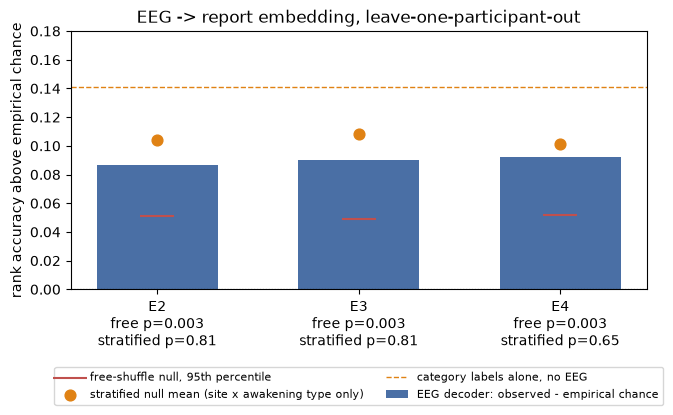

In [8]:
strat = conf[conf.null.str.startswith("within")].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(dec))
ax.bar(x, dec.above_chance, color="#4a6fa5", width=.6, label="EEG decoder: observed - empirical chance")
ax.scatter(x, dec.null_p95 - dec.null_mean, marker="_", s=600, color="#c0504d", label="free-shuffle null, 95th percentile")
ax.scatter(x, strat.null_mean - dec.null_mean, marker="o", s=60, color="#e08214", zorder=3,
           label="stratified null mean (site x awakening type only)")
cat_only = conf[conf.model.str.startswith("category")].iloc[0]
ax.axhline(cat_only.above_chance, color="#e08214", ls="--", lw=1, label="category labels alone, no EEG")
ax.axhline(0, color="k", lw=.8, ls=":")
ax.set(xticks=x, xticklabels=[f"{e}\nfree p={p1:.3f}\nstratified p={p2:.2f}"
                              for e, p1, p2 in zip(dec.epoch, dec.p_holm, strat.p_perm)],
       ylabel="rank accuracy above empirical chance", ylim=(0, .18),
       title="EEG -> report embedding, leave-one-participant-out")
ax.legend(fontsize=8, loc="upper center", ncol=2, bbox_to_anchor=(.5, -.28))
fig.tight_layout(); fig.savefig(figs / "h2_decoding.pdf"); fig.savefig(figs / "h2_decoding.png", dpi=150)
env.write_manifest(cfg, "05_h2", [tables / f for f in ["h2_decoding_by_epoch.csv", "h2_rank_scores.csv",
                                                       "h2_e4_vs_e2.csv", "h2_posthoc_awakening_type.csv",
                                                       "h2_confound_control.csv"]])